## Generative Adversarial Network (GAN)
GANs are a form of neural network in which two sub-networks (the encoder and decoder) are trained on opposing loss functions: an encoder that is trained to produce data which is indiscernable from the true data, and a decoder that is trained to discern between the data and generated data.

![gan](https://github.com/timsainb/tensorflow2-generative-models/blob/master/imgs/gan.png?raw=1)

## Load Package

In [ ]:
from keras.datasets.mnist import load_data
import matplotlib.pyplot as plt
import numpy as np
from keras.models import Sequential
from keras.layers import InputLayer, Reshape, Conv2DTranspose, LeakyReLU
from keras.layers import Dense, Conv2D, MaxPooling2D, Dropout, Flatten, Activation
from keras.utils import plot_model
from keras.optimizers import Adam
from keras.models import load_model

## Load the MNIST dataset and Data Pre-processing

In [ ]:
(trainX, trainy), (testX, testy) = load_data()

11490434/11490434 [==============================] - 1s 0us/step


In [ ]:
print('Train', trainX.shape, trainy.shape)
print('Test', testX.shape, testy.shape)

Train (60000, 28, 28) (60000,)
Test (10000, 28, 28) (10000,)


In [ ]:
trainy

array([5, 0, 4, ..., 5, 6, 8], dtype=uint8)

### Data Visualization

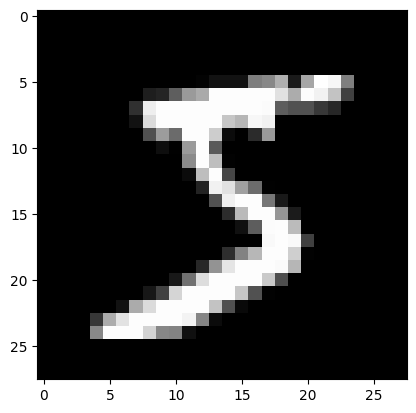

In [ ]:
plt.imshow(trainX[0], cmap="gray")

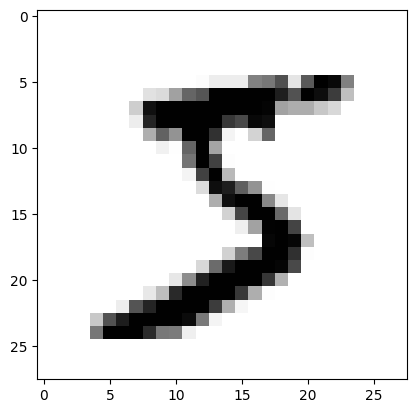

In [ ]:
plt.imshow(trainX[0], cmap='gray_r')

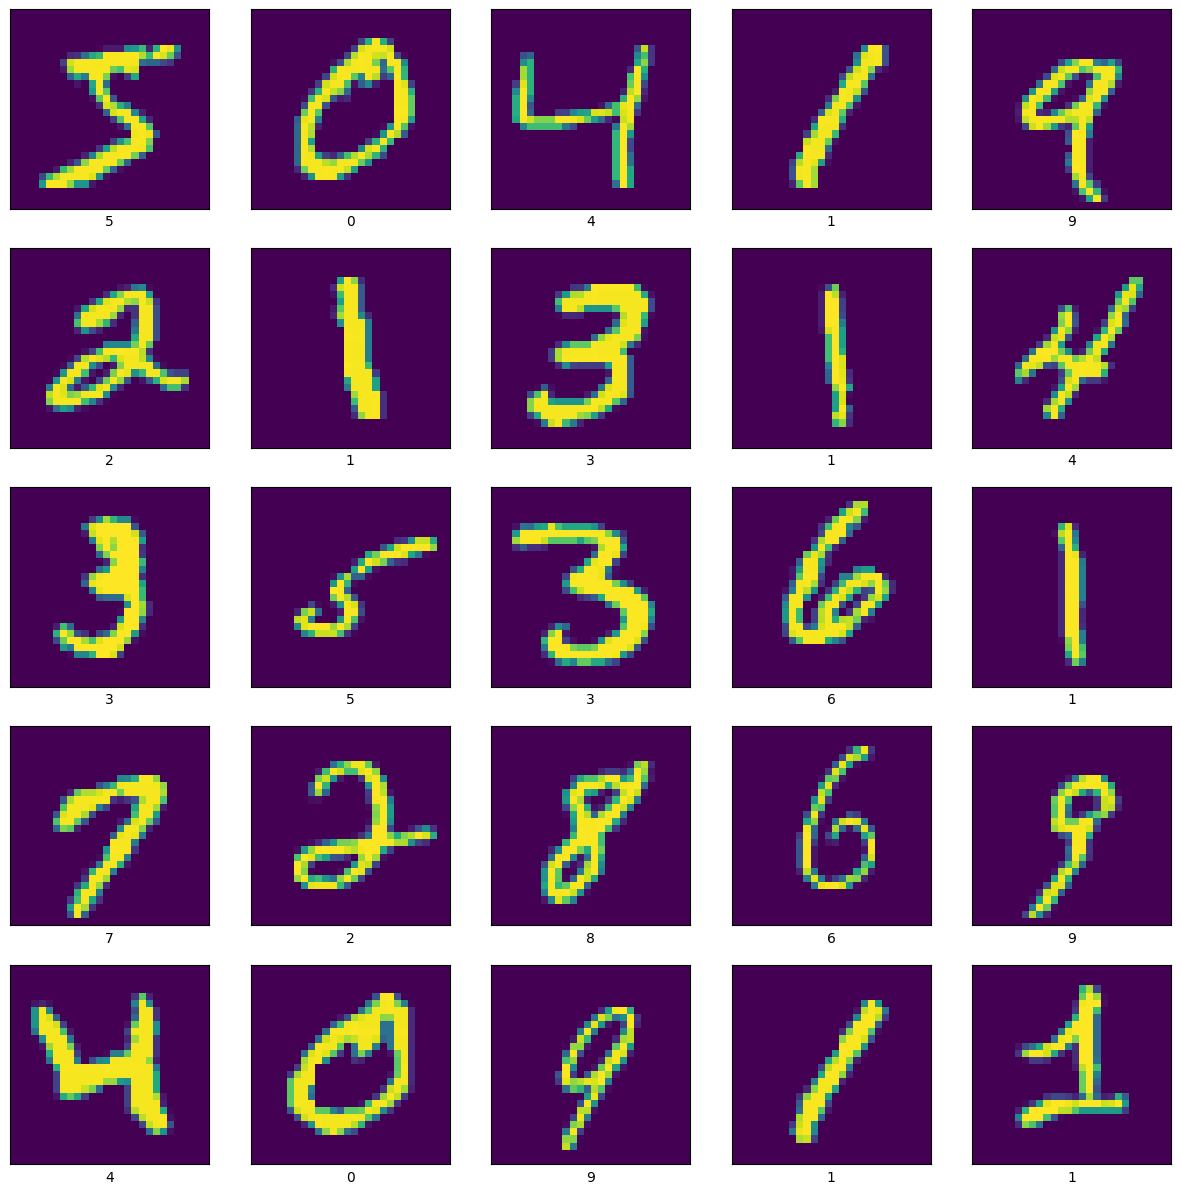

In [ ]:
plt.figure(figsize=(15,15))
for i in range(25):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.imshow(trainX[i])
    plt.xlabel(trainy[i])
plt.show()

### Data Normalization

In [ ]:
trainX = np.expand_dims(trainX, -1)
testX = np.expand_dims(testX, -1)

trainX = trainX / 255.0
testX = testX / 255.0

## Build Discriminator

In [ ]:
def define_discriminator(in_shape=(28,28,1)):
	model = Sequential()
	model.add(Conv2D(64, (3,3), strides=(2, 2), padding='same', input_shape=in_shape))
	model.add(LeakyReLU(alpha=0.2))
	model.add(Dropout(0.4))
	model.add(Conv2D(64, (3,3), strides=(2, 2), padding='same'))
	model.add(LeakyReLU(alpha=0.2))
	model.add(Dropout(0.4))
	model.add(Flatten())
	model.add(Dense(1, activation='sigmoid'))
	# compile model
	opt = Adam(lr=0.0002, beta_1=0.5)
	model.compile(loss='binary_crossentropy', optimizer=opt, metrics=['accuracy'])
	return model

In [ ]:
discriminator = define_discriminator()
discriminator.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 14, 14, 64)        640       
                                                                 
 leaky_re_lu (LeakyReLU)     (None, 14, 14, 64)        0         
                                                                 
 dropout (Dropout)           (None, 14, 14, 64)        0         
                                                                 
 conv2d_1 (Conv2D)           (None, 7, 7, 64)          36928     
                                                                 
 leaky_re_lu_1 (LeakyReLU)   (None, 7, 7, 64)          0         
                                                                 
 dropout_1 (Dropout)         (None, 7, 7, 64)          0         
                                                                 
 flatten (Flatten)           (None, 3136)              0

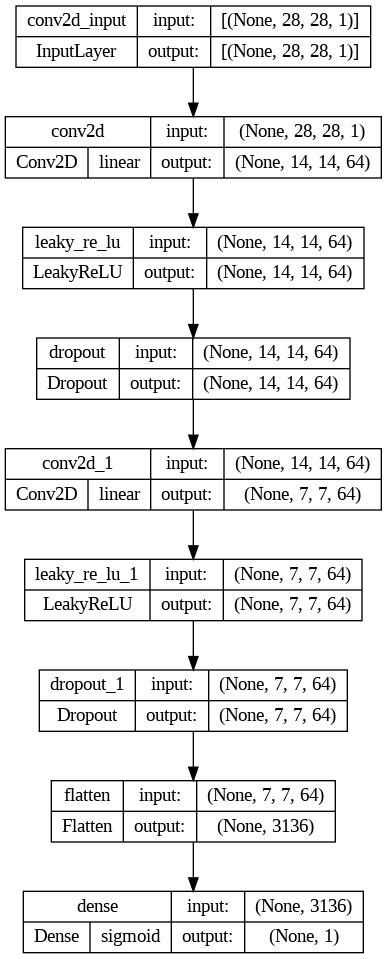

In [ ]:
plot_model(discriminator, show_shapes=True, show_layer_names=True, show_layer_activations=True)

## Build Generator

In [ ]:
def define_generator(latent_dim):
	model = Sequential()

	n_nodes = 128 * 7 * 7
	model.add(Dense(n_nodes, input_dim=latent_dim))
	model.add(LeakyReLU(alpha=0.2))
	model.add(Reshape((7, 7, 128)))

	model.add(Conv2DTranspose(128, (4,4), strides=(2,2), padding='same'))
	model.add(LeakyReLU(alpha=0.2))

	model.add(Conv2DTranspose(128, (4,4), strides=(2,2), padding='same'))
	model.add(LeakyReLU(alpha=0.2))
	model.add(Conv2D(1, (7,7), activation='sigmoid', padding='same'))
	return model

In [ ]:
generator = define_generator(100)
generator.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_1 (Dense)             (None, 6272)              633472    
                                                                 
 leaky_re_lu_2 (LeakyReLU)   (None, 6272)              0         
                                                                 
 reshape (Reshape)           (None, 7, 7, 128)         0         
                                                                 
 conv2d_transpose (Conv2DTr  (None, 14, 14, 128)       262272    
 anspose)                                                        
                                                                 
 leaky_re_lu_3 (LeakyReLU)   (None, 14, 14, 128)       0         
                                                                 
 conv2d_transpose_1 (Conv2D  (None, 28, 28, 128)       262272    
 Transpose)                                           

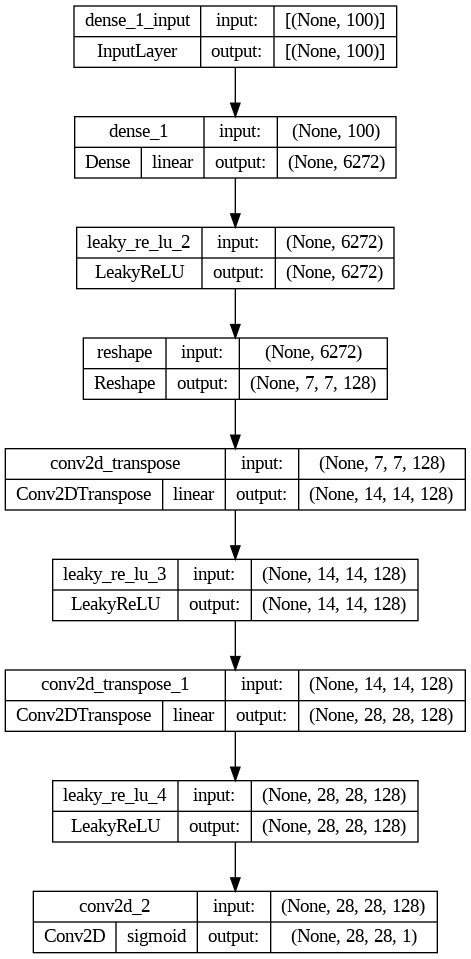

In [ ]:
plot_model(generator, show_shapes=True, show_layer_names=True, show_layer_activations=True)

## Build GAN

In [ ]:
def define_gan(generator, discriminator):

	discriminator.trainable = False

	model = Sequential()
	model.add(generator)
	model.add(discriminator)

	opt = Adam(lr=0.0002, beta_1=0.5)
	model.compile(loss='binary_crossentropy', optimizer=opt)
	return model

In [ ]:
gan = define_gan(generator, discriminator)
gan.summary()

Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 sequential_1 (Sequential)   (None, 28, 28, 1)         1164289   
                                                                 
 sequential (Sequential)     (None, 1)                 40705     
                                                                 
Total params: 1204994 (4.60 MB)
Trainable params: 1164289 (4.44 MB)
Non-trainable params: 40705 (159.00 KB)
_________________________________________________________________


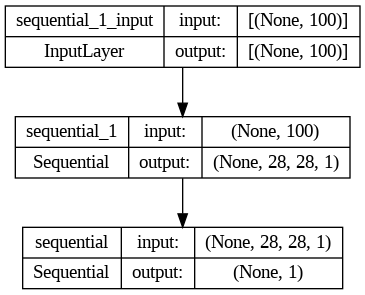

In [ ]:
plot_model(gan, show_shapes=True, show_layer_names=True, show_layer_activations=True)

## Train GAN

### Define configauration parameters

In [ ]:
batch_size = 256
n_epochs = 30
bat_per_epo = int(trainX.shape[0] / batch_size)
half_batch = int(batch_size / 2)
latent_dim = 100

### Create helper functions first

#### define a function generate real samples from training set images

In [ ]:
def generate_real_samples(dataset, n_samples):
	ix = np.random.randint(0, dataset.shape[0], n_samples)
	X = dataset[ix]
	y = np.ones((n_samples, 1))
	return X, y

#### define a function generate fake samples from normal distrubion by using generator model

In [ ]:
def generate_fake_samples(generator, latent_dim, n_samples):
  x_input = np.random.randn(latent_dim * n_samples)
  x_input = x_input.reshape(n_samples, latent_dim)
  X = generator.predict(x_input)
  y = np.zeros((n_samples, 1))
  return X, y

#### define a funciton save a plot of generated images

In [ ]:
def save_plot(examples, epoch, n=10):
	for i in range(n * n):
		plt.subplot(n, n, 1 + i)
		plt.axis('off')
		plt.imshow(examples[i, :, :, 0], cmap='gray_r')
	filename = 'generated_plot_e%03d.png' % (epoch+1)
	plt.savefig(filename)
	plt.close()

#### define a function evaluate the model

In [ ]:
def evaluate(epoch, generator, discriminator, dataset, latent_dim, n_samples=100):

	X_real, y_real = generate_real_samples(dataset, n_samples)
	_, acc_real = discriminator.evaluate(X_real, y_real, verbose=0)

	x_fake, y_fake = generate_fake_samples(generator, latent_dim, n_samples)
	_, acc_fake = discriminator.evaluate(x_fake, y_fake, verbose=0)

	print('>Accuracy real: %.0f%%, fake: %.0f%%' % (acc_real*100, acc_fake*100))

	save_plot(x_fake, epoch)
	filename = 'generator_model_%03d.h5' % (epoch + 1)
	generator.save(filename)

### Traning main loop

In [ ]:
for i in range(n_epochs):

    for j in range(bat_per_epo):

      X_real, y_real = generate_real_samples(trainX, half_batch)
      X_fake, y_fake = generate_fake_samples(generator, latent_dim, half_batch)
      X, y = np.vstack((X_real, X_fake)), np.vstack((y_real, y_fake))
      d_loss, _ = discriminator.train_on_batch(X, y)

      X_gan = np.random.randn(latent_dim * batch_size)
      X_gan = X_gan.reshape(batch_size, latent_dim)
      y_gan = np.ones((batch_size, 1))
      g_loss = gan.train_on_batch(X_gan, y_gan)

      print('>%d, %d/%d, d=%.3f, g=%.3f' % (i+1, j+1, bat_per_epo, d_loss, g_loss))

    if (i+1) % 10 == 0:
      evaluate(i, generator, discriminator, trainX, latent_dim)

4/4 [==============================] - 11s 3ms/step
>1, 1/234, d=0.700, g=0.820
4/4 [==============================] - 0s 3ms/step
>1, 2/234, d=0.656, g=0.924
4/4 [==============================] - 0s 3ms/step
>1, 3/234, d=0.633, g=0.972
4/4 [==============================] - 0s 3ms/step
>1, 4/234, d=0.637, g=0.890
4/4 [==============================] - 0s 3ms/step
>1, 5/234, d=0.657, g=0.756
4/4 [==============================] - 0s 3ms/step
>1, 6/234, d=0.647, g=0.698
4/4 [==============================] - 0s 3ms/step
>1, 7/234, d=0.612, g=0.690
4/4 [==============================] - 0s 4ms/step
>1, 8/234, d=0.567, g=0.693
4/4 [==============================] - 0s 3ms/step
>1, 9/234, d=0.513, g=0.699
4/4 [==============================] - 0s 4ms/step
>1, 10/234, d=0.467, g=0.707
4/4 [==============================] - 0s 3ms/step
>1, 11/234, d=0.425, g=0.715
4/4 [==============================] - 0s 3ms/step
>1, 12/234, d=0.395, g=0.725
4/4 [==============================] - 0s 5ms/st

/usr/local/lib/python3.10/dist-packages/keras/src/engine/training.py:3079: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


4/4 [==============================] - 0s 3ms/step
>11, 1/234, d=0.696, g=0.667
4/4 [==============================] - 0s 4ms/step
>11, 2/234, d=0.690, g=0.695
4/4 [==============================] - 0s 3ms/step
>11, 3/234, d=0.686, g=0.732
4/4 [==============================] - 0s 4ms/step
>11, 4/234, d=0.687, g=0.731
4/4 [==============================] - 0s 4ms/step
>11, 5/234, d=0.688, g=0.691
4/4 [==============================] - 0s 6ms/step
>11, 6/234, d=0.687, g=0.679
4/4 [==============================] - 0s 4ms/step
>11, 7/234, d=0.688, g=0.710
4/4 [==============================] - 0s 4ms/step
>11, 8/234, d=0.693, g=0.754
4/4 [==============================] - 0s 3ms/step
>11, 9/234, d=0.696, g=0.756
4/4 [==============================] - 0s 5ms/step
>11, 10/234, d=0.699, g=0.692
4/4 [==============================] - 0s 3ms/step
>11, 11/234, d=0.702, g=0.666
4/4 [==============================] - 0s 5ms/step
>11, 12/234, d=0.698, g=0.690
4/4 [==============================] 

4/4 [==============================] - 0s 3ms/step
>21, 1/234, d=0.686, g=0.657
4/4 [==============================] - 0s 3ms/step
>21, 2/234, d=0.689, g=0.665
4/4 [==============================] - 0s 3ms/step
>21, 3/234, d=0.696, g=0.693
4/4 [==============================] - 0s 3ms/step
>21, 4/234, d=0.688, g=0.697
4/4 [==============================] - 0s 3ms/step
>21, 5/234, d=0.692, g=0.721
4/4 [==============================] - 0s 3ms/step
>21, 6/234, d=0.695, g=0.768
4/4 [==============================] - 0s 3ms/step
>21, 7/234, d=0.691, g=0.749
4/4 [==============================] - 0s 6ms/step
>21, 8/234, d=0.688, g=0.694
4/4 [==============================] - 0s 3ms/step
>21, 9/234, d=0.693, g=0.681
4/4 [==============================] - 0s 5ms/step
>21, 10/234, d=0.693, g=0.718
4/4 [==============================] - 0s 4ms/step
>21, 11/234, d=0.685, g=0.722
4/4 [==============================] - 0s 5ms/step
>21, 12/234, d=0.694, g=0.680
4/4 [==============================] 

## Use your trained Generator Model to generate new images

1/1 [==============================] - 0s 141ms/step


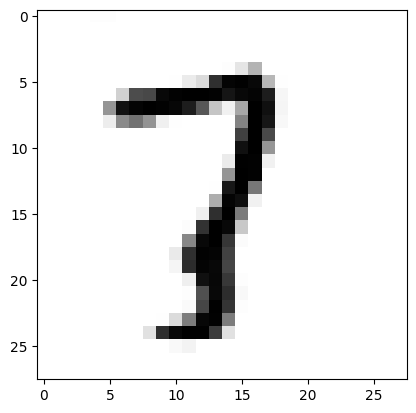

In [ ]:
model = load_model('/content/generator_model_030.h5')

vector = np.random.randn(100 * 1)
vector = vector.reshape(1, latent_dim)

X = model.predict(vector)

plt.imshow(X[0, :, :, 0], cmap='gray_r')
plt.show()

You can learn more from this Machine Learning Mastery Blog

https://machinelearningmastery.com/how-to-develop-a-generative-adversarial-network-for-an-mnist-handwritten-digits-from-scratch-in-keras/